# Assignment 1

In [7]:
import csv
from datetime import datetime
import json
import os
from bs4 import BeautifulSoup
import kagglehub
from kagglehub import KaggleDatasetAdapter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from requests.exceptions import HTTPError
import seaborn as sns
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [9]:
def parse_web_page(url):
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    
    response = requests.get(url, headers=headers)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, 'html.parser')

    for script_or_style in soup(['script', 'style']):
        script_or_style.decompose()

    text = soup.get_text(separator=' ', strip=True)
    
    return text

print("--- КСД ---")
print(parse_web_page('https://ksd.ua/?srsltid=AU7gw4VOS28BknICba87_00vPTGSxUEWi-fC1C6vZtDO2xXFVS2NWKeJ')[:255])

print("\n--- ЧНУ Відділ міжнародних зв'язків ---")
print(parse_web_page('https://www.chnu.edu.ua/mizhnarodna-diialnist/pro-nas/kontakty/')[:255])

--- КСД ---
Інтернет-магазин КСД | КСД - простір книжок, що захоплюють ​ ​ Безкоштовна* доставка вiд 990 грн КСДкоїни 0 коїнів Бонуси 0 грн Авторизуватись КСДкоїни 0 коїнів Бонуси 0 грн Авторизуватись Повідомлення Мої замовлення Бібліотека Про КСД Новини Програма лоя

--- ЧНУ Відділ міжнародних зв'язків ---
Контакти - Чернівецький національний університет імені Юрія Федьковича Перейти до основного вмісту rector@chnu.edu.ua 58002, Україна, м. Чернівці, вул. Коцюбинського, 2 eng ukr Університет Загальні відомості Про університет Керівництво Факультети та інсти


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [16]:
def parse_api(api_url):
  headers = {'User-Agent': 'Mozilla/5.0'}

  response = requests.get(api_url, headers=headers)
  response.raise_for_status()

  data = response.json()
    
  with open('result.json', 'w', encoding='utf-8') as f:
    json.dump(data, f, ensure_ascii=False, indent=4)

parse_api('https://api.github.com/')
print('Дані успішно збережено в result.json')

Дані успішно збережено в result.json


## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [24]:
def parse_json(date):
    file_path = os.path.join('resources', 'weather.json')
    
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
    except FileNotFoundError:
        print(f"Помилка: файл не знайдено за шляхом {file_path}")
        return []

    try:
        target_date = datetime.strptime(date, "%Y-%m-%d").strftime("%Y-%m-%d")
    except ValueError:
        target_date = date

    daily_list = data.get('daily', [])

    return [item for item in daily_list if item.get('date') == target_date]

target_date = '2024-8-18'
print(parse_json(target_date))

[{'date': '2024-08-18', 'max_temperature': 32.5, 'min_temperature': 22.5, 'precipitation': 0.0, 'wind_speed': 15.5, 'humidity': 65, 'weather_description': 'Clear sky'}]


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [31]:
def parse_csv(date):
    file_path = os.path.join('resources', 'weather.csv')
    if not os.path.exists(file_path):
        file_path = 'weather.csv'

    result = []

    try:
        with open(file_path, mode='r', encoding='utf-8') as f:
            reader = csv.DictReader(f)
            for row in reader:
                if row.get('CET', '').strip() == date.strip():
                    result.append(dict(row))

    except FileNotFoundError:
        print(f"Помилка: файл не знайдено за шляхом {file_path}")
        return []

    return result

target_date = '1997-5-22'
print(parse_csv(target_date))

[{'CET': '1997-5-22', 'Max TemperatureC': '25', 'Mean TemperatureC': '18', 'Min TemperatureC': '10', 'Dew PointC': '11', 'MeanDew PointC': '8', 'Min DewpointC': '6', 'Max Humidity': '88', ' Mean Humidity': '54', ' Min Humidity': '34', ' Max Sea Level PressurehPa': '1017', ' Mean Sea Level PressurehPa': '1015', ' Min Sea Level PressurehPa': '1012', ' Max VisibilityKm': '10', ' Mean VisibilityKm': '10', ' Min VisibilitykM': '10', ' Max Wind SpeedKm/h': '11', ' Mean Wind SpeedKm/h': '3', ' Max Gust SpeedKm/h': '', 'Precipitationmm': '0.00', ' CloudCover': '3', ' Events': '', 'WindDirDegrees': '277'}]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

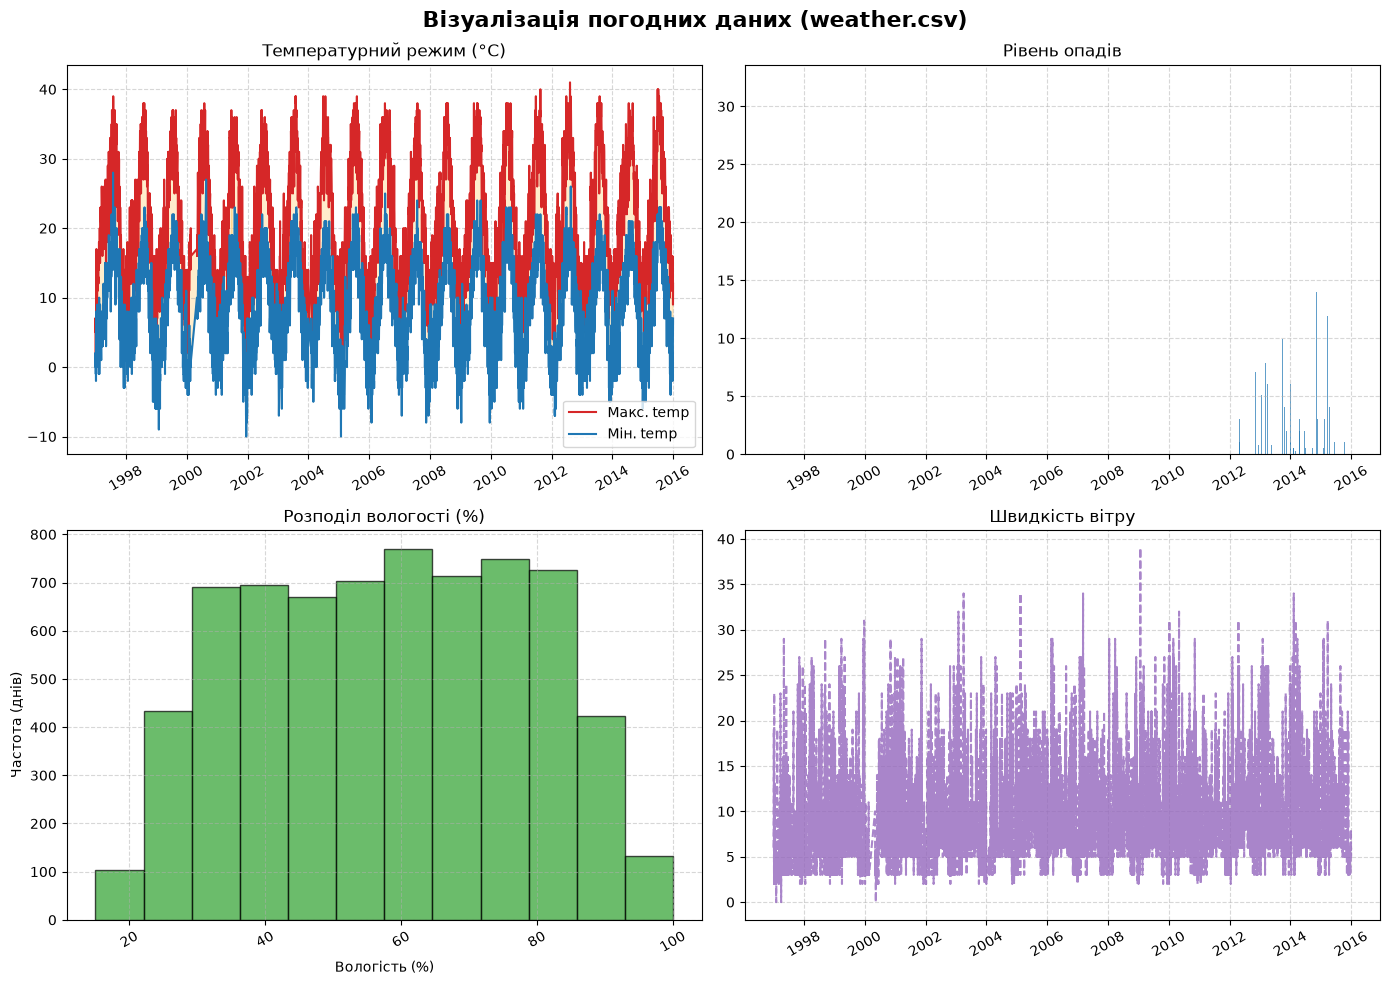

Візуалізацію успішно створено та збережено в 'weather_visualization.png'


In [38]:
def visualize_data():

  file_path = os.path.join('resources', 'weather.csv')
  if not os.path.exists(file_path):
    file_path = 'weather.csv'

  if not os.path.exists(file_path):
    print(f'Помилка: файл weather.csv не знайдено за шляхом {file_path}')
    return

  try:
    df = pd.read_csv(file_path, sep=None, engine='python')
  except Exception:
    df = pd.read_csv(file_path)

  df.columns = df.columns.str.strip()

  date_col = None
  for col in df.columns:
    if col.upper() == 'CET' or 'DATE' in col.upper():
      date_col = col
      break

  if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df = df.dropna(subset=[date_col]).sort_values(date_col)
  else:
    print('Помилка: не знайдено колонку з датою (CET)')
    return

  cols_lower = {c.lower(): c for c in df.columns}

  def find_col(keywords):
    for kw_group in keywords:
      for c_lower, c_orig in cols_lower.items():
        if all(kw in c_lower for kw in kw_group):
          return c_orig
    return None

  max_temp_col = find_col([['max', 'temp'], ['max', 'temperature']])
  min_temp_col = find_col([['min', 'temp'], ['min', 'temperature']])
  mean_temp_col = find_col( [['mean', 'temp'], ['mean', 'temperature'], ['temp']])
  precip_col = find_col([['precip'], ['rain'], ['опад']])
  humidity_col = find_col([['mean', 'humid'], ['humid'], ['волог']])
  wind_col = find_col([['mean', 'wind'], ['wind'], ['вітер']])

  fig, axes = plt.subplots(2, 2, figsize=(14, 10))
  fig.suptitle(
      'Візуалізація погодних даних (weather.csv)', fontsize=16, fontweight='bold'
  )

  if max_temp_col and min_temp_col:
    axes[0, 0].plot(df[date_col], df[max_temp_col], color='tab:red', label='Макс. temp',linewidth=1.5,)
    axes[0, 0].plot(df[date_col], df[min_temp_col], color='tab:blue', label='Мін. temp',linewidth=1.5,)
    axes[0, 0].fill_between(df[date_col], df[min_temp_col], df[max_temp_col], color='orange', alpha=0.2,)
    axes[0, 0].set_title('Температурний режим (°C)')
    axes[0, 0].legend()
  elif mean_temp_col:
    axes[0, 0].plot(df[date_col], df[mean_temp_col], color='tab:red', linewidth=1.5)
    axes[0, 0].set_title('Середня температура (°C)')
  else:
    axes[0, 0].text(0.5, 0.5,'Колонку температури не знайдено', ha='center', va='center', transform=axes[0, 0].transAxes,)

  # --- Графік 2: Опади ---
  if precip_col:
    precip_data = pd.to_numeric(df[precip_col], errors='coerce').fillna(0)
    axes[0, 1].bar(df[date_col], precip_data, color='tab:blue', width=1.5, alpha=0.7)
    axes[0, 1].set_title('Рівень опадів')
  else:
    axes[0, 1].text(0.5, 0.5, 'Колонку опадів не знайдено', ha='center', va='center', transform=axes[0, 1].transAxes,)

  # --- Графік 3: Вологість ---
  if humidity_col:
    humid_data = pd.to_numeric(df[humidity_col], errors='coerce').dropna()
    axes[1, 0].hist(humid_data, bins=12, color='tab:green', edgecolor='black', alpha=0.7)
    axes[1, 0].set_title('Розподіл вологості (%)')
    axes[1, 0].set_xlabel('Вологість (%)')
    axes[1, 0].set_ylabel('Частота (днів)')
  else:
    axes[1, 0].text(0.5, 0.5, 'Колонку вологості не знайдено', ha='center', va='center', transform=axes[1, 0].transAxes,)

  # --- Графік 4: Швидкість вітру ---
  if wind_col:
    wind_data = pd.to_numeric(df[wind_col], errors='coerce')
    axes[1, 1].plot(df[date_col], wind_data, color='tab:purple', linestyle='--', alpha=0.8)
    axes[1, 1].set_title('Швидкість вітру')
  else:
    axes[1, 1].text(0.5, 0.5, 'Колонку вітру не знайдено', ha='center', va='center', transform=axes[1, 1].transAxes,)

  for ax in axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=30)

  plt.tight_layout()
  output_filename = 'weather_visualization.png'
  plt.savefig(output_filename, dpi=300, bbox_inches='tight')
  plt.show()

  print(f"Візуалізацію успішно створено та збережено в '{output_filename}'")

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

Пропущені значення після імпутації:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


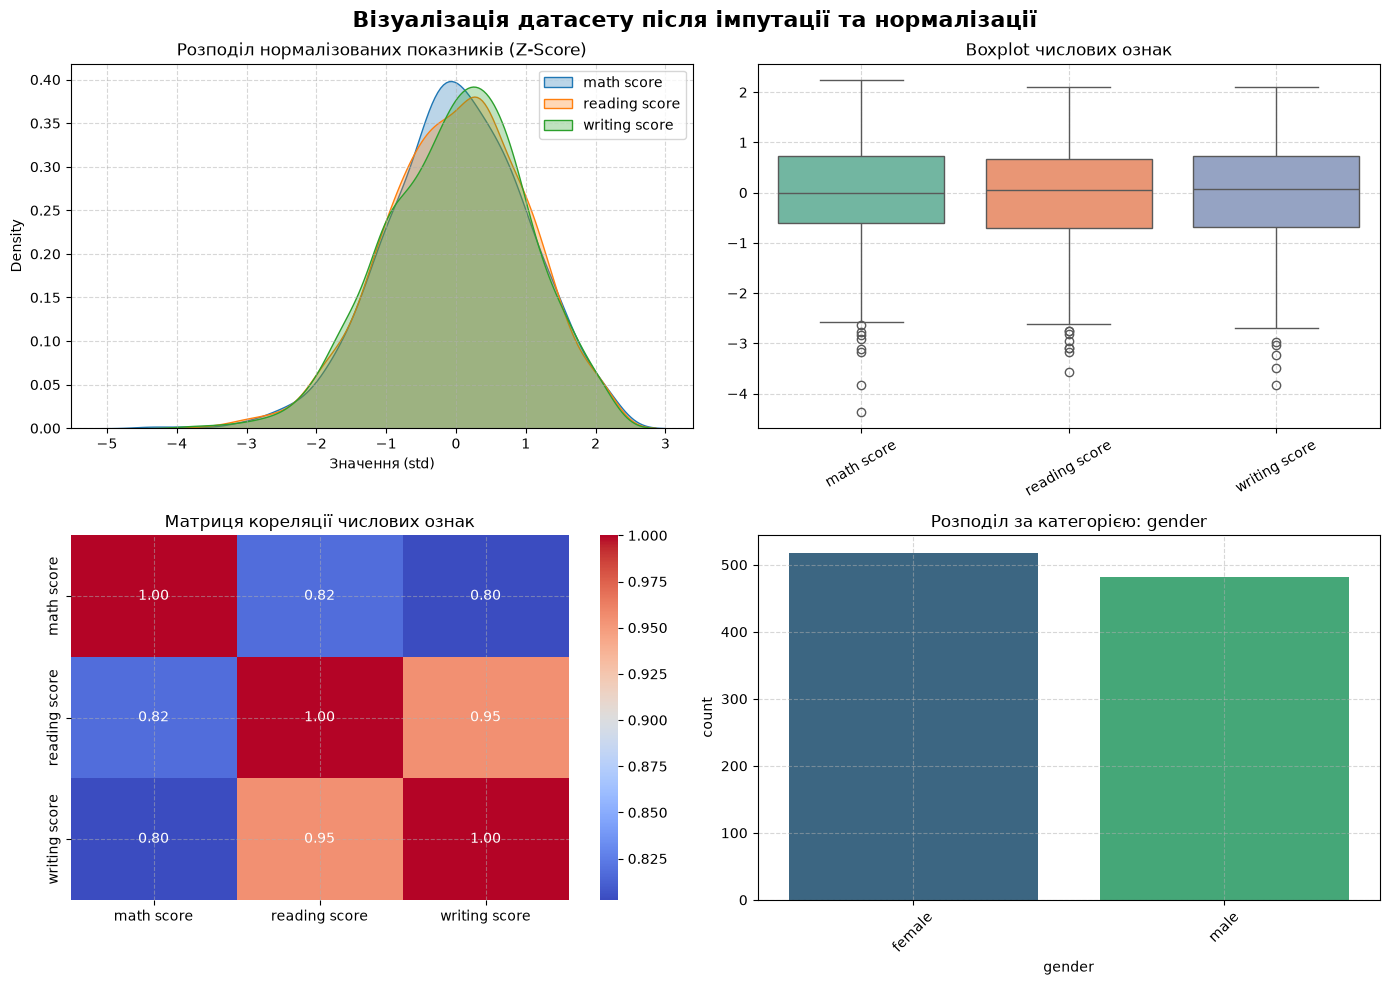

Графіки успішно збережено у файл 'students_performance_visualization.png'


In [9]:
def load_dataset(url, csv_file):
  df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, url, csv_file)
  return df


def impute_data(df):
  df_imputed = df.copy()

  numeric_cols = df_imputed.select_dtypes(include=[np.number]).columns
  categorical_cols = df_imputed.select_dtypes(exclude=[np.number]).columns

  if len(numeric_cols) > 0:
    knn_imputer = KNNImputer(n_neighbors=5)
    df_imputed[numeric_cols] = knn_imputer.fit_transform(
        df_imputed[numeric_cols]
    )

  if len(categorical_cols) > 0:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    df_imputed[categorical_cols] = cat_imputer.fit_transform(
        df_imputed[categorical_cols]
    )

  print('Пропущені значення після імпутації:')
  print(df_imputed.isnull().sum())
  return df_imputed


def normalize_data(df):
  df_normalized = df.copy()
  numeric_cols = df_normalized.select_dtypes(include=[np.number]).columns

  # Застосовуємо Z-Score Normalization (StandardScaler) для числових колонок
  if len(numeric_cols) > 0:
    scaler = StandardScaler()
    df_normalized[numeric_cols] = scaler.fit_transform(df_normalized[numeric_cols])
      
  return df_normalized


def visualize_data(df):
  numeric_cols = df.select_dtypes(include=[np.number]).columns
  categorical_cols = df.select_dtypes(exclude=[np.number]).columns

  fig, axes = plt.subplots(2, 2, figsize=(14, 10))
  fig.suptitle( 'Візуалізація датасету після імпутації та нормалізації', fontsize=16, fontweight='bold',)

  if len(numeric_cols) > 0:
    for col in numeric_cols[:4]:  # Перші кілька колонок
      sns.kdeplot(df[col], ax=axes[0, 0], label=col, fill=True, alpha=0.3)
    axes[0, 0].set_title('Розподіл нормалізованих показників (Z-Score)')
    axes[0, 0].set_xlabel('Значення (std)')
    axes[0, 0].legend()

  if len(numeric_cols) > 0:
    sns.boxplot(data=df[numeric_cols], ax=axes[0, 1], palette='Set2')
    axes[0, 1].set_title('Boxplot числових ознак')
    axes[0, 1].tick_params(axis='x', rotation=30)

  if len(numeric_cols) > 1:
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1, 0], fmt='.2f',)
    axes[1, 0].set_title('Матриця кореляції числових ознак')

    if len(categorical_cols) > 0:
        cat_col = categorical_cols[0]
        sns.countplot( x=cat_col, hue=cat_col,  data=df, ax=axes[1, 1], palette='viridis', legend=False, order=df[cat_col].value_counts().index)
        axes[1, 1].set_title(f'Розподіл за категорією: {cat_col}')
        axes[1, 1].tick_params(axis='x', rotation=45)
  elif len(numeric_cols) >= 2:
    sns.scatterplot( x=numeric_cols[0], y=numeric_cols[1], data=df, ax=axes[1, 1], color='purple',)
    axes[1, 1].set_title(f'Залежність {numeric_cols[0]} від {numeric_cols[1]}')

  for ax in axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)

  plt.tight_layout()
  output_filename = 'students_performance_visualization.png'
  plt.savefig(output_filename, dpi=300, bbox_inches='tight')
  plt.show()

  print(f"Графіки успішно збережено у файл '{output_filename}'")


if __name__ == '__main__':
  df = load_dataset( 'ilayaraja07/data-cleaning-feature-imputation', 'Students_Performance_knn.csv',)
  df = impute_data(df)
  df = normalize_data(df)
  visualize_data(df)